In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd


#upload files

In [4]:
from google.colab import files
uploaded=files.upload()

Saving used_cars.csv to used_cars.csv


#read files

In [7]:
df=pd.read_csv('used_cars.csv')
df

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
4004,Bentley,Continental GT Speed,2023,714 mi.,Gasoline,6.0L W12 48V PDI DOHC Twin Turbo,8-Speed Automatic with Auto-Shift,C / C,Hotspur,None reported,Yes,"$349,950"
4005,Audi,S4 3.0T Premium Plus,2022,"10,900 mi.",Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$53,900"
4006,Porsche,Taycan,2022,"2,116 mi.",NaN,Electric,Automatic,Black,Black,None reported,NaN,"$90,998"
4007,Ford,F-150 Raptor,2020,"33,000 mi.",Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes,"$62,999"


# EDA

(4009, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
d

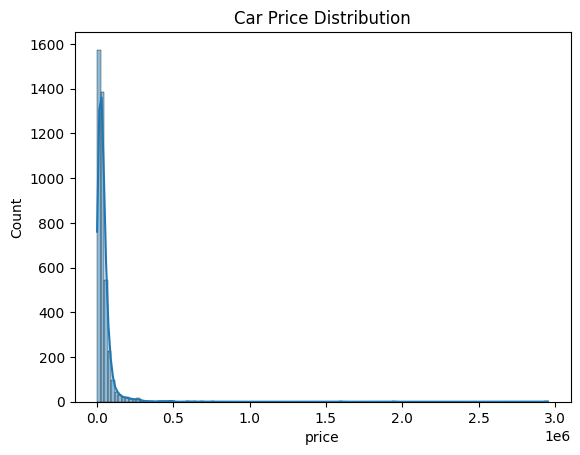

In [8]:
# Dataset shape
print(df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

# Check missing values
print(df.isnull().sum())

# Check duplicates
print("Duplicates:", df.duplicated().sum())

# Target variable distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['price'].str.replace(r'[$,]', '', regex=True).astype(float),
             kde=True)
plt.title('Car Price Distribution')
plt.show()

#DATA CLEANING

In [9]:
# Remove dollar sign and commas from price
df['price'] = (
    df['price'].astype(str)
    .str.replace(r'[$,]', '', regex=True)
    .str.strip()
)

df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Convert mileage into numeric
df['milage'] = (
    df['milage'].astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)

df['milage'] = pd.to_numeric(df['milage'], errors='coerce')

# Remove rows where target price is missing
df = df.dropna(subset=['price'])

print(df[['price', 'milage']].head())

   price   milage
0  10300  51000.0
1  38005  34742.0
2  54598  22372.0
3  15500  88900.0
4  34999   9835.0


#HANDLE MISSING VALUES

In [10]:
# Categorical columns
cat_cols = df.select_dtypes(include='object').columns

# Numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Fill missing categorical values
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

# Fill missing numerical values
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum())

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


#SEPERATE X and Y Values

In [11]:
X = df.drop('price', axis=1)
y = df['price']

print(X.shape)
print(y.shape)

(4009, 11)
(4009,)


#split test and training data

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3207, 11)
Testing data: (802, 11)


#build machine learning models

In [14]:
# Identify numerical and categorical columns from feature dataset X
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'),
         numerical_features),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

#train different models

In [15]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline

    print(name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)
    print("----------------------")

Linear Regression
MAE: 25845.252006624243
RMSE: 137153.6487656941
R2 Score: 0.07967132351601391
----------------------
Decision Tree
MAE: 23648.784141455413
RMSE: 137460.0711622759
R2 Score: 0.07555441744198832
----------------------
Random Forest
MAE: 21073.091681392154
RMSE: 134864.3173746991
R2 Score: 0.1101386590272454
----------------------


#compare model performance

In [16]:
results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by='R2 Score',
    ascending=False
))

               Model           MAE           MSE           RMSE  R2 Score
2      Random Forest  21073.091681  1.818838e+10  134864.317375  0.110139
0  Linear Regression  25845.252007  1.881112e+10  137153.648766  0.079671
1      Decision Tree  23648.784141  1.889527e+10  137460.071162  0.075554


#Visualize model performance

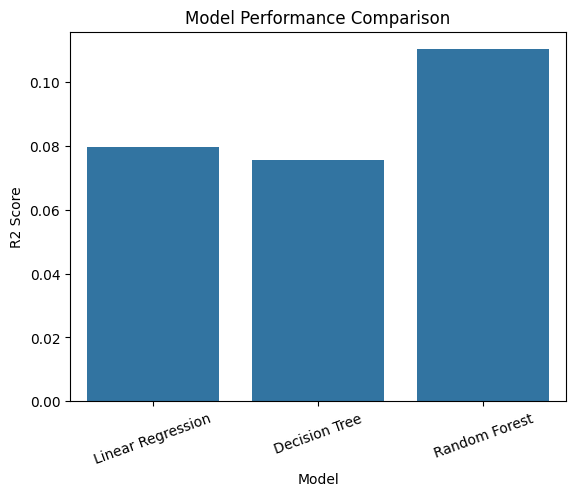

In [17]:
sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Model Performance Comparison')
plt.xticks(rotation=20)
plt.show()

#Predict used car price

In [18]:
best_model_name = results_df.sort_values(
    by='R2 Score',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


#Now predict the price of a car:

In [19]:
new_car = pd.DataFrame([{
    'brand': 'Toyota',
    'model': 'Camry',
    'model_year': 2022,
    'milage': 25000,
    'fuel_type': 'Gasoline',
    'engine': '2.5L 4 Cylinder Engine',
    'transmission': 'Automatic',
    'ext_col': 'White',
    'int_col': 'Black',
    'accident': 'None reported',
    'clean_title': 'Yes'
}])

predicted_price = best_model.predict(new_car)

print("Predicted Car Price: $", round(predicted_price[0], 2))

Predicted Car Price: $ 44983.64
